# 🎓 Day 11 — CNN & RNN Concepts DEMO NOTEBOOK

### Session Flow
| Demo | Slide | What students see |
|------|-------|-------------------|
| Demo 1 | Slide 2 | Convolution on a real image — edge detection |
| Demo 2 | Slide 2 | Step-by-step convolution window animation |
| Demo 3 | Slide 4 | Max pooling visualised |
| Demo 4 | Slides 6-7 | Pretrained ResNet predicting real images |
| Demo 5 | Slide 8 | RNN hidden state flow diagram |
| Demo 6 | Slide 10 | LSTM gate states across a sentence |


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.signal import convolve2d
from PIL import Image
import requests
from io import BytesIO
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')
print('Setup complete ✅')

Setup complete ✅


---
# 🎬 Demo 1 — Convolution on a Real Image
### Run after Slide 2 (Convolution Step by Step)

**What to say:** "We just saw convolution on a 3×3 toy grid. Now let's apply it to a real image. I'll use three different filters and you'll see what each one detects."

Image shape: (300, 400)


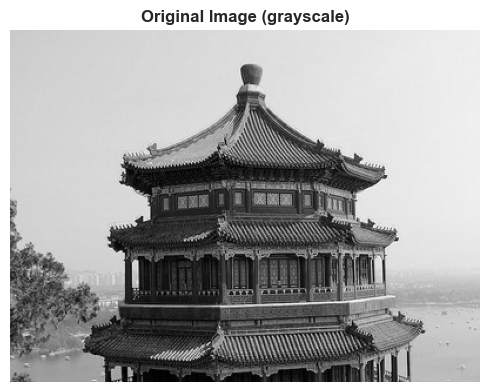

In [6]:
# Load a sample image (grayscale camera image from sklearn)
from sklearn.datasets import load_sample_image

try:
    china = load_sample_image('china.jpg')
    img_gray = np.mean(china, axis=2)  # convert to grayscale
    img_gray = img_gray[:300, :400]    # crop to reasonable size
    print(f'Image shape: {img_gray.shape}')
except:
    # Fallback: synthetic image with clear edges
    img_gray = np.zeros((200, 200))
    img_gray[50:150, 50:150] = 200     # white square
    img_gray[75:125, 75:125] = 100     # grey inner square
    img_gray += np.random.randn(200, 200) * 5  # small noise
    print('Using synthetic image (sklearn sample not available)')

plt.figure(figsize=(5, 4))
plt.imshow(img_gray, cmap='gray')
plt.title('Original Image (grayscale)', fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

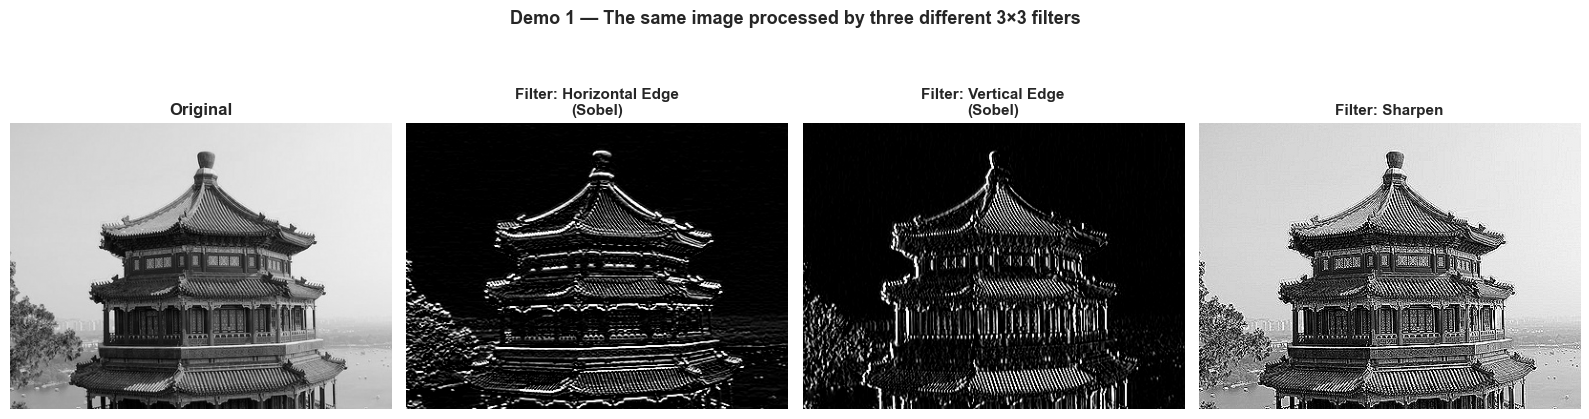

In [7]:
# Three classic filters — these are the kinds of things early CNN layers learn

filters = {
    'Horizontal Edge\n(Sobel)': np.array([[-1, -2, -1],
                                           [ 0,  0,  0],
                                           [ 1,  2,  1]], dtype=float),

    'Vertical Edge\n(Sobel)':   np.array([[-1, 0, 1],
                                           [-2, 0, 2],
                                           [-1, 0, 1]], dtype=float),

    'Sharpen':                  np.array([[ 0, -1,  0],
                                           [-1,  5, -1],
                                           [ 0, -1,  0]], dtype=float),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title('Original', fontweight='bold', fontsize=12)
axes[0].axis('off')

for ax, (name, filt) in zip(axes[1:], filters.items()):
    # Apply filter
    feature_map = convolve2d(img_gray, filt, mode='same', boundary='symm')
    # Clip for display
    feature_map = np.clip(feature_map, 0, 255)
    ax.imshow(feature_map, cmap='gray')
    ax.set_title(f'Filter: {name}', fontweight='bold', fontsize=11)
    ax.axis('off')

plt.suptitle('Demo 1 — The same image processed by three different 3×3 filters',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "Each filter responds to a different structural property of the image.
#  The horizontal Sobel filter highlights horizontal boundaries.
#  The vertical Sobel highlights vertical boundaries.
#  In a real CNN, the network LEARNS these filters automatically from data.
#  We hand-designed them here — the CNN finds them itself."
# ─────────────────────────────────────────────────────────────────────────────

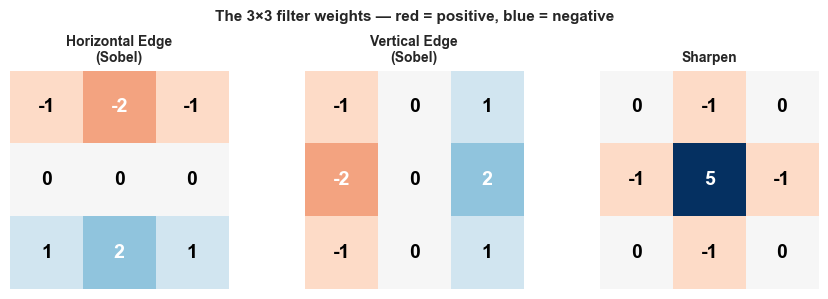

In [8]:
# Show the filter values visually — what does a 3×3 filter look like?
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, (name, filt) in zip(axes, filters.items()):
    im = ax.imshow(filt, cmap='RdBu', vmin=-5, vmax=5)
    ax.set_title(name, fontweight='bold', fontsize=10)
    # Annotate each cell with its value
    for r in range(3):
        for c in range(3):
            ax.text(c, r, str(int(filt[r,c])), ha='center', va='center',
                    fontsize=14, fontweight='bold',
                    color='white' if abs(filt[r,c]) > 1 else 'black')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('The 3×3 filter weights — red = positive, blue = negative',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "Look at the horizontal Sobel filter. The top row is all negative, bottom is all
#  positive. When this filter slides over a region where pixels go from dark above
#  to light below (a horizontal edge), the top negative weights subtract the dark
#  values and the bottom positive weights add the bright values — large response.
#  When the region is uniform, the positives and negatives cancel out — zero response."
# ─────────────────────────────────────────────────────────────────────────────

---
# 🎬 Demo 2 — Convolution Window Animation
### Run after Demo 1, still on Slide 2

**What to say:** "Let me show you exactly how the filter slides across the image. Watch the red box — that's our 3×3 filter window."

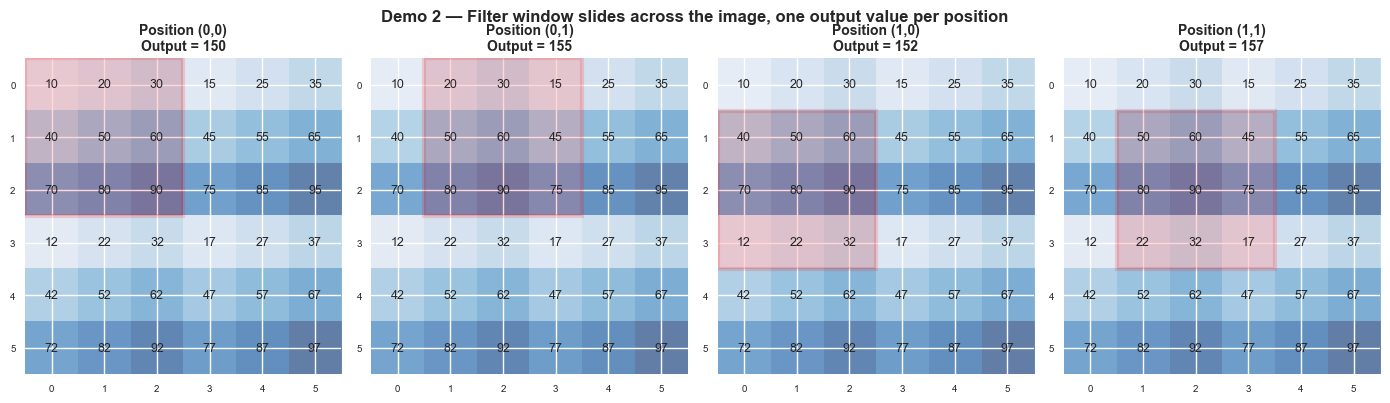

In [9]:
# Show convolution window sliding across a small patch of the image
# Use a 6x6 crop and a 3x3 identity-like filter for clarity

patch = np.array([[10, 20, 30, 15, 25, 35],
                  [40, 50, 60, 45, 55, 65],
                  [70, 80, 90, 75, 85, 95],
                  [12, 22, 32, 17, 27, 37],
                  [42, 52, 62, 47, 57, 67],
                  [72, 82, 92, 77, 87, 97]], dtype=float)

diag_filter = np.array([[1,0,0],[0,1,0],[0,0,1]], dtype=float)  # diagonal

# Show 4 positions of the sliding window
positions = [(0,0), (0,1), (1,0), (1,1)]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, (r, c) in zip(axes, positions):
    ax.imshow(patch, cmap='Blues', vmin=0, vmax=100, alpha=0.6)

    # Annotate all cell values
    for ri in range(6):
        for ci in range(6):
            ax.text(ci, ri, str(int(patch[ri,ci])), ha='center', va='center', fontsize=9)

    # Highlight the filter window
    rect = patches.Rectangle((c-0.5, r-0.5), 3, 3,
                               linewidth=3, edgecolor='red', facecolor='red', alpha=0.15)
    ax.add_patch(rect)

    # Compute the output value for this position
    region  = patch[r:r+3, c:c+3]
    out_val = np.sum(region * diag_filter)

    ax.set_title(f'Position ({r},{c})\nOutput = {out_val:.0f}', fontweight='bold', fontsize=10)
    ax.set_xticks(range(6))
    ax.set_yticks(range(6))
    ax.tick_params(labelsize=7)

plt.suptitle('Demo 2 — Filter window slides across the image, one output value per position',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "The red box is our 3×3 filter. At each position, we multiply the 9 values
#  in the window by the 9 filter weights and sum them up — that's one output number.
#  Then the window shifts by 1 pixel (stride=1) and we repeat.
#  For a 224×224 image with stride=1, that's ~50,000 positions per filter.
#  But because the SAME filter is used everywhere, there are only 9 weights to learn."
# ─────────────────────────────────────────────────────────────────────────────

---
# 🎬 Demo 3 — Max Pooling Visualised
### Run after Slide 4 (Pooling & Translation Invariance)

**What to say:** "After convolution we typically apply pooling. Let me show you what max pooling does to an actual feature map."

In [10]:
!pip install scikit-image

  Using cached scikit_image-0.26.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (15 kB)
  Using cached imageio-2.37.3-py3-none-any.whl.metadata (9.7 kB)
  Using cached lazy_loader-0.5-py3-none-any.whl.metadata (5.9 kB)
Using cached scikit_image-0.26.0-cp314-cp314-macosx_11_0_arm64.whl (12.1 MB)
Using cached imageio-2.37.3-py3-none-any.whl (317 kB)
Using cached lazy_loader-0.5-py3-none-any.whl (8.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-image]0m 3/4 [scikit-image]


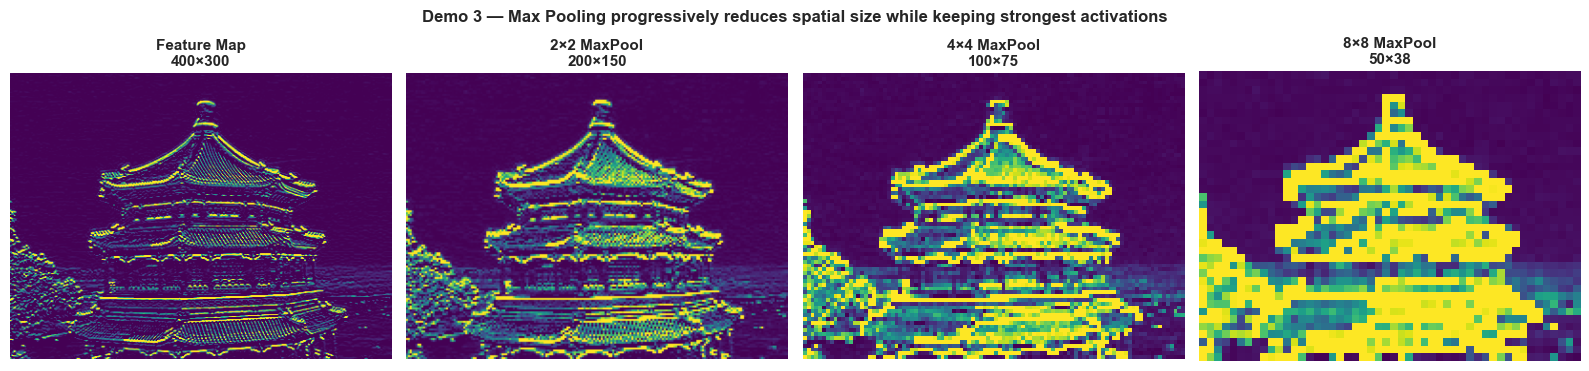

Original feature map: (300, 400)
After 2×2 pooling:    (150, 200)  (÷2)
After 4×4 pooling:    (75, 100)  (÷4)
After 8×8 pooling:    (38, 50)  (÷8)


In [11]:
# Apply conv + maxpool to the actual image
from skimage.measure import block_reduce  # max pooling via block_reduce

# Use horizontal edge filter from Demo 1
h_filter    = filters['Horizontal Edge\n(Sobel)']
feature_map = convolve2d(img_gray, h_filter, mode='same', boundary='symm')
feature_map = np.clip(feature_map, 0, 255)

# Apply 2×2 max pooling (halves spatial dimensions)
pooled_2x  = block_reduce(feature_map, block_size=(2, 2),  func=np.max)
pooled_4x  = block_reduce(feature_map, block_size=(4, 4),  func=np.max)
pooled_8x  = block_reduce(feature_map, block_size=(8, 8),  func=np.max)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = [
    f'Feature Map\n{feature_map.shape[1]}×{feature_map.shape[0]}',
    f'2×2 MaxPool\n{pooled_2x.shape[1]}×{pooled_2x.shape[0]}',
    f'4×4 MaxPool\n{pooled_4x.shape[1]}×{pooled_4x.shape[0]}',
    f'8×8 MaxPool\n{pooled_8x.shape[1]}×{pooled_8x.shape[0]}',
]
maps = [feature_map, pooled_2x, pooled_4x, pooled_8x]

for ax, fm, title in zip(axes, maps, titles):
    ax.imshow(fm, cmap='viridis')
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.axis('off')

plt.suptitle('Demo 3 — Max Pooling progressively reduces spatial size while keeping strongest activations',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Original feature map: {feature_map.shape}')
print(f'After 2×2 pooling:    {pooled_2x.shape}  (÷2)')
print(f'After 4×4 pooling:    {pooled_4x.shape}  (÷4)')
print(f'After 8×8 pooling:    {pooled_8x.shape}  (÷8)')

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "Notice the edge structure is still visible even after aggressive pooling.
#  The WHICH edges are present information survives — the exact pixel location
#  information is lost. That's exactly what we want: edge detection that is
#  robust to small shifts in position."
# ─────────────────────────────────────────────────────────────────────────────

---
# 🎬 Demo 4 — Pretrained ResNet Image Classification
### Run after Slide 7 (Famous Architectures) or Slide 8 (Transfer Learning)

**What to say:** "ResNet-50 was trained on 1.2 million images across 1000 categories. Let's use it right now — zero training required on our side — and classify some images."

In [12]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms
import json

# Load pretrained ResNet-50
print('Loading pretrained ResNet-50...')
resnet = models.resnet50(weights='IMAGENET1K_V2')
resnet.eval()
print(f'ResNet-50 loaded ✅  ({sum(p.numel() for p in resnet.parameters()):,} parameters)')

# ImageNet class labels
IMAGENET_URL = 'https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json'
try:
    labels = json.loads(requests.get(IMAGENET_URL, timeout=5).text)
    print(f'Loaded {len(labels)} ImageNet class labels')
except:
    # Fallback minimal label set
    labels = [f'class_{i}' for i in range(1000)]
    print('Using fallback labels')

# Transform pipeline for ResNet
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def classify_image(img_array, top_k=5):
    """Classify a numpy image array using ResNet-50."""
    img_pil = Image.fromarray(img_array.astype(np.uint8))
    tensor  = preprocess(img_pil).unsqueeze(0)
    with torch.no_grad():
        logits = resnet(tensor)
    probs   = torch.softmax(logits, dim=1)[0]
    top_idx = probs.topk(top_k).indices.numpy()
    return [(labels[i], probs[i].item()) for i in top_idx]

print('classify_image() ready ✅')

Loading pretrained ResNet-50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /Users/shash/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100.0%


ResNet-50 loaded ✅  (25,557,032 parameters)
Loaded 1000 ImageNet class labels
classify_image() ready ✅


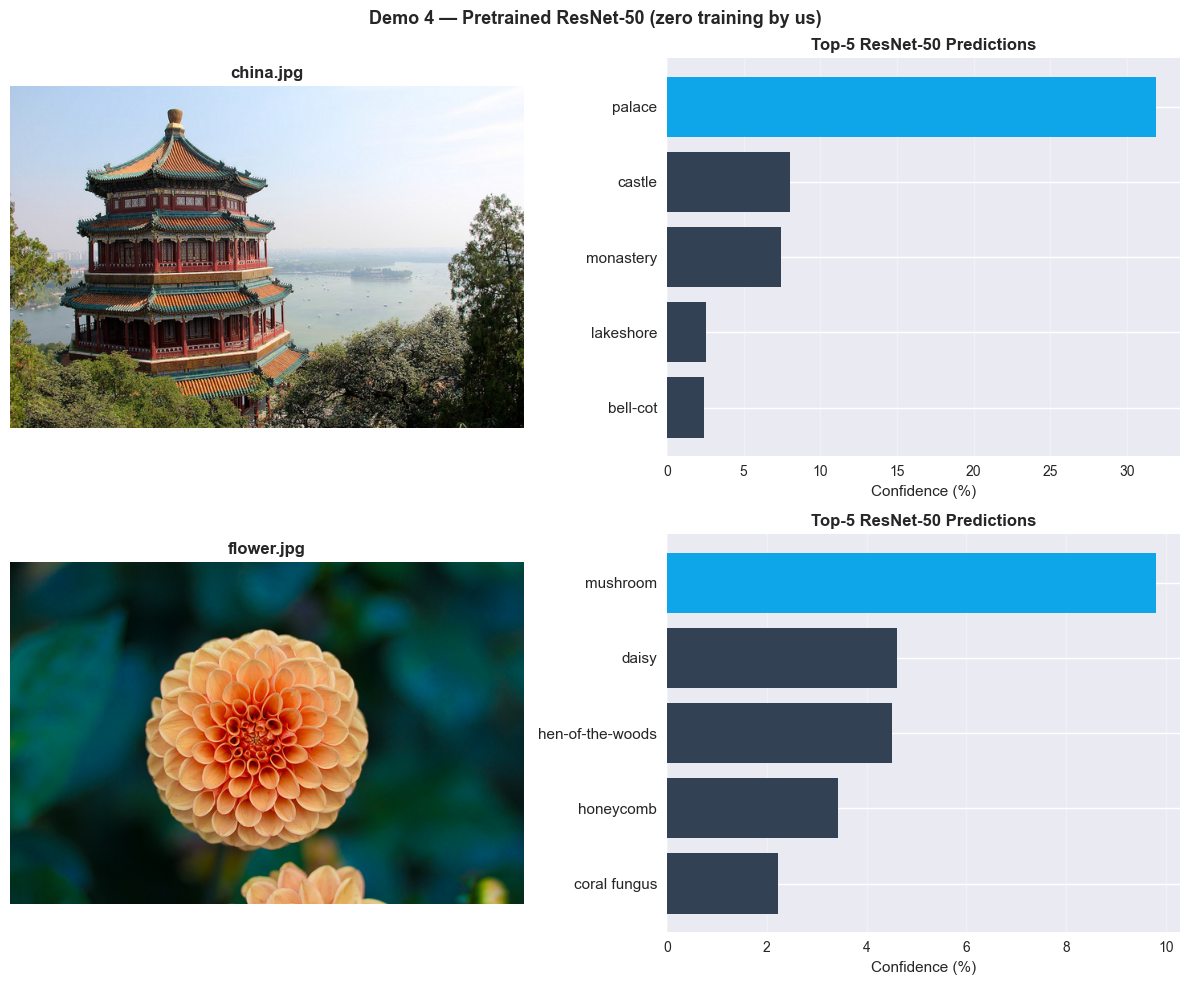

In [13]:
# Use sklearn sample images for classification
from sklearn.datasets import load_sample_image

sample_images = {}
for name in ['china.jpg', 'flower.jpg']:
    try:
        sample_images[name] = load_sample_image(name)
    except:
        pass

if not sample_images:
    print('No sample images found — creating synthetic test image')
    # Use a random coloured image as fallback
    sample_images['random'] = np.random.randint(0, 256, (224, 224, 3), dtype=np.uint8)

fig, axes = plt.subplots(len(sample_images), 2, figsize=(12, 5 * len(sample_images)))
if len(sample_images) == 1:
    axes = [axes]

for row_axes, (img_name, img_arr) in zip(axes, sample_images.items()):
    ax_img, ax_bar = row_axes

    # Show image
    ax_img.imshow(img_arr)
    ax_img.set_title(img_name, fontweight='bold')
    ax_img.axis('off')

    # Classify
    preds = classify_image(img_arr)

    # Bar chart of top-5
    class_names = [p[0] for p in preds]
    probs       = [p[1] * 100 for p in preds]
    colours     = ['#0EA5E9' if i == 0 else '#334155' for i in range(len(preds))]

    ax_bar.barh(range(len(preds))[::-1], probs, color=colours)
    ax_bar.set_yticks(range(len(preds))[::-1])
    ax_bar.set_yticklabels(class_names, fontsize=11)
    ax_bar.set_xlabel('Confidence (%)')
    ax_bar.set_title('Top-5 ResNet-50 Predictions', fontweight='bold')
    ax_bar.grid(axis='x', alpha=0.3)

plt.suptitle('Demo 4 — Pretrained ResNet-50 (zero training by us)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "We wrote zero training code. We loaded a model someone else trained on
#  1.2 million images, passed our image through it, and got predictions.
#  This is the practical power of transfer learning.
#  If you want to build a dog breed classifier, you don't train ResNet from scratch.
#  You take this model, freeze the first 49 layers, replace just the last layer
#  with one that outputs 120 dog breed probabilities, and train only that layer
#  on your 1000 labelled dog photos."
# ─────────────────────────────────────────────────────────────────────────────

---
# 🎬 Demo 5 — RNN Hidden State Flow
### Run after Slide 9 (Why RNNs Exist)

**What to say:** "The key idea of an RNN is the hidden state — a vector that summarises everything the network has seen so far. Let me show you what it looks like as the network processes a sentence word by word."

In [14]:
import torch
import torch.nn as nn

# Build a tiny character-level RNN for demonstration
torch.manual_seed(42)

sentence = "I love machine learning"
words     = sentence.split()

# Simple word embeddings (random — this is untrained, just to show the mechanics)
vocab     = {w: i for i, w in enumerate(words)}
n_words   = len(vocab)
embed_dim = 8
hidden_dim = 16

embedding = nn.Embedding(n_words, embed_dim)
rnn_cell  = nn.RNNCell(embed_dim, hidden_dim)

h = torch.zeros(1, hidden_dim)  # initial hidden state (all zeros)

hidden_states = [h.detach().numpy().flatten()]
hidden_norms  = [0.0]

print('Hidden state evolution through the sentence:\n')
print(f'{"Initial state":20s}  norm = {np.linalg.norm(hidden_states[0]):.4f}  {"[" + ", ".join(f"{x:.2f}" for x in hidden_states[0][:4]) + ", ...]"}' )

for word in words:
    idx   = torch.tensor([vocab[word]])
    embed = embedding(idx)          # word → vector
    h     = rnn_cell(embed, h)      # update hidden state
    h_np  = h.detach().numpy().flatten()
    norm  = np.linalg.norm(h_np)
    hidden_states.append(h_np)
    hidden_norms.append(norm)
    print(f'After "{word:10s}"  norm = {norm:.4f}  [{" ".join(f"{x:.2f}" for x in h_np[:4])}, ...]')

print('\nThe final hidden state is a compressed summary of the entire sentence.')

Hidden state evolution through the sentence:

Initial state         norm = 0.0000  [0.00, 0.00, 0.00, 0.00, ...]
After "I         "  norm = 1.7074  [-0.26 0.04 -0.73 0.78, ...]
After "love      "  norm = 1.6491  [-0.70 -0.59 -0.58 0.00, ...]
After "machine   "  norm = 1.9823  [0.19 0.28 0.38 -0.43, ...]
After "learning  "  norm = 1.9365  [0.45 0.75 -0.51 -0.55, ...]

The final hidden state is a compressed summary of the entire sentence.


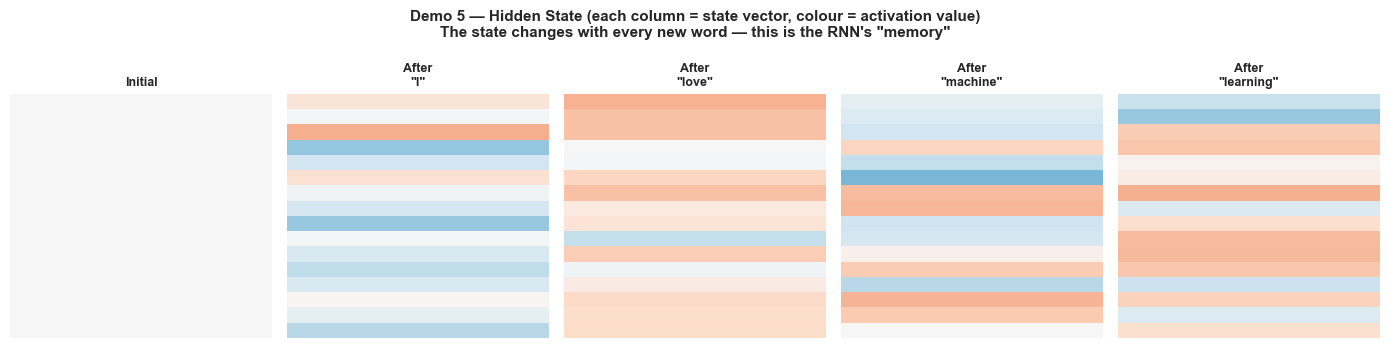

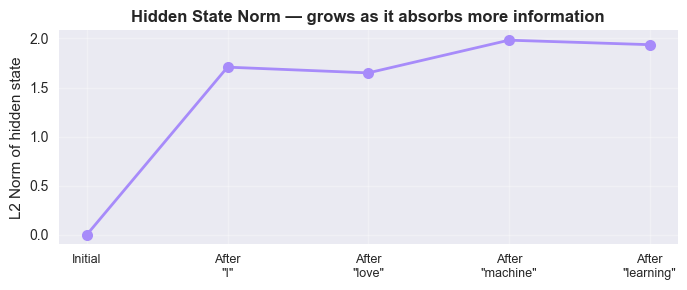

In [15]:
# Visualise the hidden state as a heatmap at each time step
fig, axes = plt.subplots(1, len(hidden_states), figsize=(14, 3.5))

labels_x = ['Initial'] + [f'After\n"{w}"' for w in words]

for ax, h_state, label in zip(axes, hidden_states, labels_x):
    ax.imshow(h_state.reshape(-1, 1), cmap='RdBu', vmin=-2, vmax=2, aspect='auto')
    ax.set_title(label, fontsize=9, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('Demo 5 — Hidden State (each column = state vector, colour = activation value)\nThe state changes with every new word — this is the RNN\'s "memory"',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# Norm evolution
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(len(hidden_norms)), hidden_norms, 'o-', color='#A78BFA', linewidth=2, markersize=8)
ax.set_xticks(range(len(labels_x)))
ax.set_xticklabels(labels_x, fontsize=9)
ax.set_title('Hidden State Norm — grows as it absorbs more information', fontweight='bold')
ax.set_ylabel('L2 Norm of hidden state')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "Each column in the heatmap is the hidden state vector at that time step.
#  As the RNN reads each word, the colours change — the state vector is being
#  updated to incorporate new information while retaining what it knew before.
#  The final state (after 'learning') is what gets passed to the output layer
#  to make a prediction — it's a compressed representation of the whole sentence."
# ─────────────────────────────────────────────────────────────────────────────

---
# 🎬 Demo 6 — LSTM Gate States Across a Sentence
### Run after Slide 10 (LSTM)

**What to say:** "LSTMs have three gates — forget, input, and output — that open and close at each time step. Let me show you the actual gate activations as an LSTM processes a sentence."

In [16]:
torch.manual_seed(0)

# Use a longer sentence to show gate dynamics
long_sentence = "The film I watched last week was absolutely amazing"
long_words     = long_sentence.split()
n_long         = len(long_words)

# Build a small LSTM
vocab_long   = {w: i for i, w in enumerate(set(long_words))}
embed_long   = nn.Embedding(len(vocab_long), 8)
lstm         = nn.LSTMCell(8, 32)

h = torch.zeros(1, 32)
c = torch.zeros(1, 32)

# Manually compute LSTM gates to extract them
# (nn.LSTMCell doesn't expose gates directly — we compute them ourselves)
W_ih = lstm.weight_ih.detach()  # shape (4*hidden, input)
W_hh = lstm.weight_hh.detach()  # shape (4*hidden, hidden)
b_ih = lstm.bias_ih.detach()
b_hh = lstm.bias_hh.detach()

forget_gates = []
input_gates  = []
output_gates = []
cell_norms   = []
hidden_dim   = 32

for word in long_words:
    idx   = torch.tensor([vocab_long.get(word, 0)])
    embed = embed_long(idx).detach()

    # LSTM gate computation (manual)
    gates_raw = embed @ W_ih.T + b_ih + h @ W_hh.T + b_hh  # (1, 4*hidden)
    i_gate = torch.sigmoid(gates_raw[:, :hidden_dim])           # input gate
    f_gate = torch.sigmoid(gates_raw[:, hidden_dim:2*hidden_dim]) # forget gate
    g_gate = torch.tanh(  gates_raw[:, 2*hidden_dim:3*hidden_dim]) # cell gate
    o_gate = torch.sigmoid(gates_raw[:, 3*hidden_dim:])          # output gate

    c = f_gate * c + i_gate * g_gate
    h = o_gate * torch.tanh(c)

    forget_gates.append(f_gate.detach().numpy().flatten()[:8])  # first 8 units
    input_gates.append(i_gate.detach().numpy().flatten()[:8])
    output_gates.append(o_gate.detach().numpy().flatten()[:8])
    cell_norms.append(np.linalg.norm(c.detach().numpy()))

print('Gate activations extracted ✅')
print(f'Words processed: {long_words}')

Gate activations extracted ✅
Words processed: ['The', 'film', 'I', 'watched', 'last', 'week', 'was', 'absolutely', 'amazing']


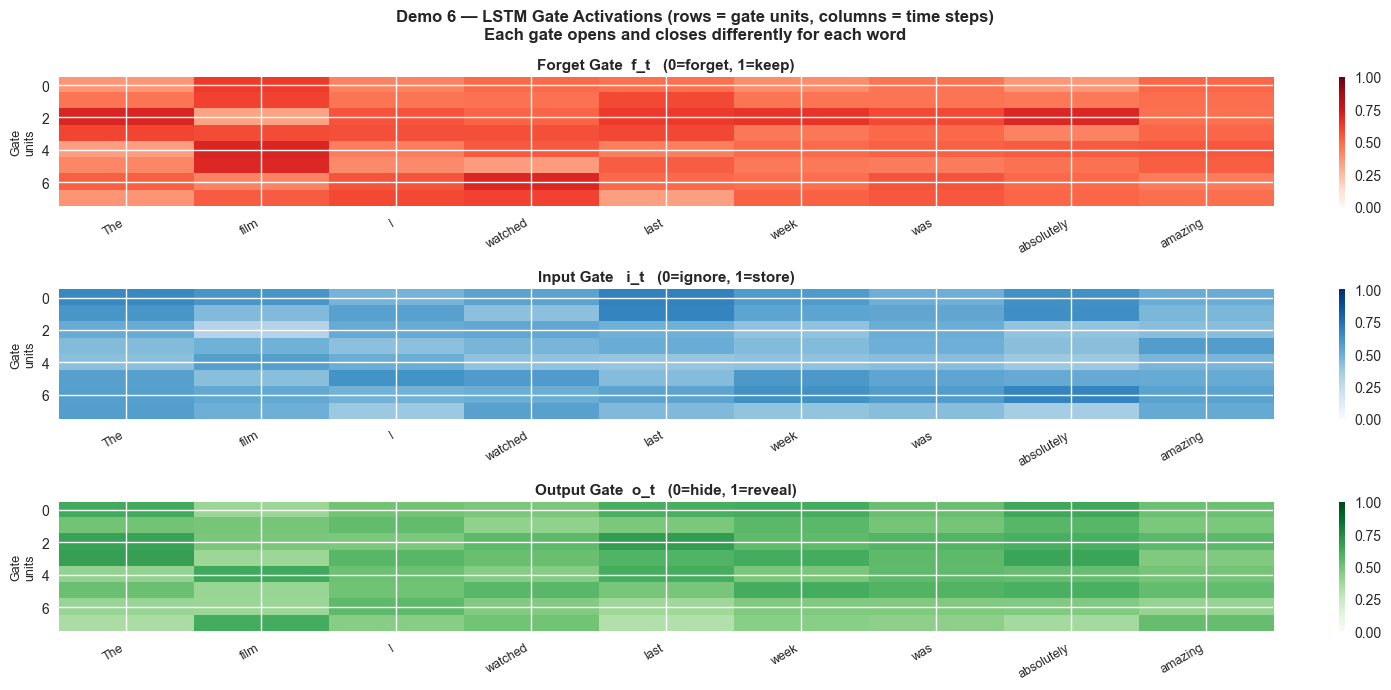

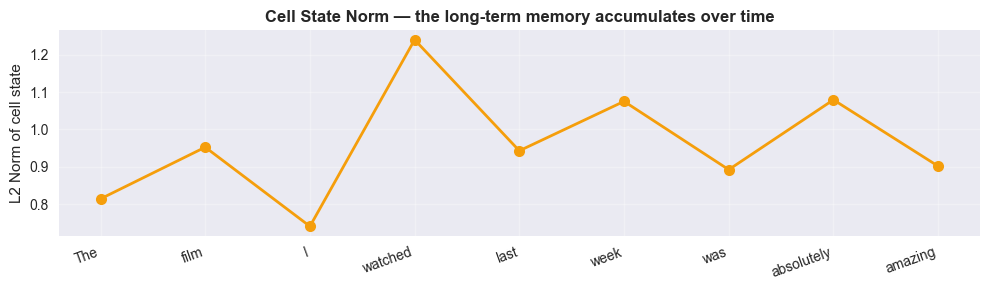

In [17]:
# Visualise gate activations as heatmaps across time
fig, axes = plt.subplots(3, 1, figsize=(14, 7))

gate_data = [
    (np.array(forget_gates).T, 'Forget Gate  f_t   (0=forget, 1=keep)', 'Reds'),
    (np.array(input_gates).T,  'Input Gate   i_t   (0=ignore, 1=store)', 'Blues'),
    (np.array(output_gates).T, 'Output Gate  o_t   (0=hide, 1=reveal)',  'Greens'),
]

for ax, (data, title, cmap) in zip(axes, gate_data):
    im = ax.imshow(data, cmap=cmap, vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(n_long))
    ax.set_xticklabels(long_words, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel('Gate\nunits', fontsize=9)
    ax.set_title(title, fontweight='bold', fontsize=11)
    plt.colorbar(im, ax=ax, fraction=0.02)

plt.suptitle('Demo 6 — LSTM Gate Activations (rows = gate units, columns = time steps)\nEach gate opens and closes differently for each word',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Cell state norm evolution
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(range(n_long), cell_norms, 'o-', color='#F59E0B', linewidth=2, markersize=8)
ax.set_xticks(range(n_long))
ax.set_xticklabels(long_words, rotation=20, ha='right')
ax.set_title('Cell State Norm — the long-term memory accumulates over time', fontweight='bold')
ax.set_ylabel('L2 Norm of cell state')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ── TALKING POINT ────────────────────────────────────────────────────────────
# "Look at the forget gate heatmap — notice how the brightness varies by word.
#  Some words cause the network to 'open' the forget gate (high values = keep memory).
#  Other words trigger it to forget (low values = clear old information).
#
#  The cell state norm (bottom chart) grows over time — the LSTM is accumulating
#  information as it reads the sentence. This is the long-term memory highway.
#
#  Key point: this is an UNTRAINED network — these gate patterns are random.
#  After training on real data, the forget gate would learn to keep 'film'
#  in memory until it reaches 'amazing' and needs to connect them for sentiment analysis."
# ─────────────────────────────────────────────────────────────────────────────

---
# 🎬 Bonus Demo — Vanishing Gradient Comparison: Vanilla RNN vs LSTM
### Run if time allows, after Slide 10

**What to say:** "Let me show you the vanishing gradient problem we discussed empirically — comparing gradient norms through a vanilla RNN vs an LSTM across 30 time steps."

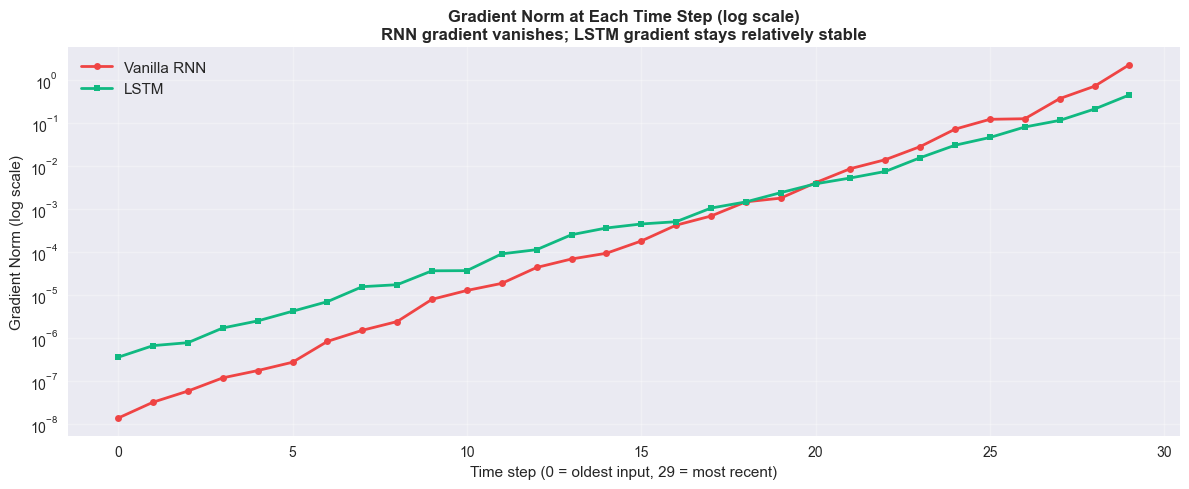

RNN   gradient at step 0 (oldest): 1.35e-08
LSTM  gradient at step 0 (oldest): 3.53e-07

RNN ratio (step 0 / step 29):  5.86e-09
LSTM ratio (step 0 / step 29): 7.76e-07


In [18]:
torch.manual_seed(42)

# Compare gradient magnitudes: vanilla RNN vs LSTM
seq_len    = 30
input_dim  = 10
hidden_dim = 20

rnn_model  = nn.RNN(input_dim, hidden_dim, batch_first=True)
lstm_model = nn.LSTM(input_dim, hidden_dim, batch_first=True)

x = torch.randn(1, seq_len, input_dim, requires_grad=True)

def get_grad_norms(model, is_lstm=False):
    """Run forward + backward and collect gradient norms at each time step."""
    # Create a fresh input for each model
    x_in = torch.randn(1, seq_len, input_dim)
    x_in.requires_grad_(True)

    if is_lstm:
        out, _ = model(x_in)
    else:
        out, _ = model(x_in)

    # Sum of last output as a scalar loss
    loss = out[:, -1, :].sum()
    loss.backward()

    # Gradient norm at each input time step
    grad = x_in.grad  # shape: (1, seq_len, input_dim)
    norms = [grad[0, t, :].norm().item() for t in range(seq_len)]
    return norms

rnn_grad_norms  = get_grad_norms(rnn_model,  is_lstm=False)
lstm_grad_norms = get_grad_norms(lstm_model, is_lstm=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.semilogy(range(seq_len), rnn_grad_norms,  'o-', color='#EF4444', linewidth=2, label='Vanilla RNN', markersize=5)
ax.semilogy(range(seq_len), lstm_grad_norms, 's-', color='#10B981', linewidth=2, label='LSTM',         markersize=5)

ax.set_title('Gradient Norm at Each Time Step (log scale)\nRNN gradient vanishes; LSTM gradient stays relatively stable',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Time step (0 = oldest input, 29 = most recent)')
ax.set_ylabel('Gradient Norm (log scale)')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'RNN   gradient at step 0 (oldest): {rnn_grad_norms[0]:.2e}')
print(f'LSTM  gradient at step 0 (oldest): {lstm_grad_norms[0]:.2e}')
print(f'\nRNN ratio (step 0 / step 29):  {rnn_grad_norms[0] / rnn_grad_norms[-1]:.2e}')
print(f'LSTM ratio (step 0 / step 29): {lstm_grad_norms[0] / lstm_grad_norms[-1]:.2e}')

---
# 💬 Discussion Questions
### Use these to close the session (last 5 minutes, back on Slide 12)

1. **"You have a dataset of 50,000 chest X-rays labelled as normal or abnormal. Which architecture would you use and why?"**  
   Expected: CNN (image data) + transfer learning (ResNet pretrained on ImageNet or CheXNet)

2. **"You want to predict the next word in a sentence given the last 10 words. CNN, RNN, or LSTM?"**  
   Expected: LSTM or GRU (sequential dependency), or Transformer (but that's next session)

3. **"Why does the same CNN filter work for detecting edges in both a photo of a dog AND a photo of a car?"**  
   Expected: edges are a fundamental structural property of natural images regardless of content

4. **"If you were building a speech recognition system (audio → text), which architecture families would you combine?"**  
   Expected: CNN on spectrogram (frequency patterns) + RNN/LSTM (temporal sequence)

5. **"The ResNet paper introduced a 152-layer network. Why could they train 152 layers when previous deep networks with 20+ layers degraded?"**  
   Expected: skip connections provide a gradient highway — gradients can flow directly from output to early layers without multiplying through 152 sets of weights